# Feature Importance Analyses for Mislocalized Variants

We select for the interpretable CellProfiler features that contribute most significantly in the XGBoost Classifier to help distinguish the mislocalized variants from their respective reference alleles.

In [14]:
import os
import random
import operator
from tqdm import tqdm
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functools import reduce
from pycytominer.feature_select import feature_select
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
import umap

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *
from utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

np.random.seed(42)
random.seed(42)

## 1. Load feature importance and classifier info

### 1.1 Feature importance for each variant

In [2]:
imaging_summary_clinvar_total = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar = imaging_summary_clinvar_total.filter(
    pl.col("AUROC_Mean_GFP").is_not_null()
)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)

print("Number of hits:", imaging_summary_clinvar_hits.shape[0])
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

Number of hits: 233


In [3]:
imaging_summary_clinvar_hits.filter(
    pl.col("Gene")=="MLH1"
).unique("Metadata_Bio_Batch")

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,…,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,i64,f64,str,…,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str
"""MLH1""","""MLH1_Val185Gly""",9.817385,0.001483,10.645651,0.000041,"""2024_12_Batch_11-12""",true,true,true,true,true,true,true,false,true,false,0.993991,0.995265,0.963568,0.982215,0.966987,0.956537,0.987598,0.955677,0.995945,0.995939,0.977438,0.976831,0.971459,0.994584,0.992042,"""MLH1""","""ENSG00000076242""",2713,200837.0,"""CCSBVarC003200""",…,3.7011828e7,"""3p22.2""","""reviewed by expert panel""",5.0,"""ACMG2013,ACMG2016,ACMG2021,ACM…","""N""","""ClinGen:CA011003,UniProtKB:P40…",2.0,90272.0,3.7011828e7,"""T""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000106769""","""-""","""-""","""554T>G ""","""Val185Gly""","""NM_000249.4""",3.0,"""1_Pathogenic""",95.47,0.0,"""['609310']""","""autosomal dominant""","""Rare genetic immune disease; R…",3,"""LYNCH SYNDROME 2""",95.47,0.0,"""<10""",""">90"""


In [4]:
imaging_summary_clinvar.shape

(933, 566)

### 1.2 Select for the CP features with importance > 1e-3 for each variant

In [ ]:
# allele_meta_df = pl.DataFrame()
# allele_meta_df_dict, img_well_qc_sum_dict = {}, {}
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     for batch_id in bio_rep_batches:
#         allele_meta_df_batch = pl.DataFrame()
#         platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
#         for platemap in platemaps:
#             platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
#             allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
#                                         platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
#                                         how="diagonal_relaxed").sort("plate_map_name")
#             allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
#             # display(allele_meta_df.head())
#         allele_meta_df = pl.concat([
#             allele_meta_df,
#             allele_meta_df_batch
#         ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
#     allele_meta_df_dict[bio_rep] = allele_meta_df_batch

#     img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
#     img_well_qc_sum = img_well_qc_sum.with_columns(
#         pl.col("channel").replace("DAPI", "DNA").alias("channel")
#     )
#     img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
#     img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
#         pl.col("is_bg").max().alias("is_bg"),
#         pl.col("s2n_ratio").mean().alias("s2n_ratio")
#     ).with_columns(pl.lit("Morph").alias("channel"))
#     img_well_qc_sum = pl.concat([
#         img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
#         img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
#     ], how="vertical_relaxed")
#     img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

In [5]:
# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
#         feat_df_batch = feat_df.with_columns(
#             [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
#         ).with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#        ).filter(
#             (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
#             &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

In [6]:
# key_alleles_df = imaging_summary_clinvar.to_pandas()
# feat_df = pl.DataFrame()
# importance_thres = 1e-3
# # top_num = 5
# for j, allele in tqdm(key_alleles_df.iterrows()):
#     batch_list = list(feat_import_df_feat.filter(
#         pl.col("Metadata_gene_allele")==allele["gene_allele"]
#     ).unique("Metadata_Batch")["Metadata_Batch"])
#     allele_df = pl.DataFrame()
#     for i, batch in enumerate(batch_list):
#         batch_df = feat_import_df_feat.filter(
#             (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
#         )
#         feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
#         batch_df = batch_df.filter(
#             ~pl.all_horizontal(pl.col(feat_cols).is_null())
#         )
#         non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
#         batch_df_col = (
#             batch_df.select(non_null_gfp).mean()
#            .transpose(include_header=True)
#            .filter(pl.col("column_0") > importance_thres)
#            .sort("column_0", descending=True)
#            # .head(top_num)#["column"]
#            # .to_list()
#         )
#         if not allele_df.is_empty():
#             allele_df = allele_df.join(
#                 batch_df_col.with_columns(
#                     pl.col("column_0").alias(batch),
#                     pl.col("column").alias("index"),
#                 ).select("index", batch),
#                 on="index",
#                 how="full",
#                 coalesce=True
#             )
#         else:
#             allele_df = batch_df_col.with_columns(
#                 pl.col("column_0").alias(batch),
#                 pl.col("column").alias("index"),
#             ).select("index", batch)
            
#     allele_df = allele_df.with_columns(
#         pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
#         pl.col("index").alias("cp_feature")
#     ).select(
#         pl.col(["cp_feature", "feat_importance"])
#     ).rename(
#         {"feat_importance": allele["gene_allele"]}
#     )
#     if not feat_df.is_empty():
#         feat_df = feat_df.join(
#             allele_df,
#             left_on="cp_feature",
#             right_on="cp_feature",
#             how="full",
#             coalesce=True
#         )
#     else:
#         feat_df = allele_df

915it [02:45,  5.54it/s]


In [8]:
# feat_df.write_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

## 2. Loading CP profile

In [5]:
feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")
ref_var_cell_all_prof_df = pl.read_parquet(
    "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_int_featselect.parquet"
)
ref_var_cell_all_prof_df.shape

(2856956, 150)

In [6]:
ref_var_cell_all_prof_df.head()

Metadata_CellID,Metadata_gene_allele,Metadata_Well,Metadata_Plate,Metadata_node_type,Cells_Texture_Correlation_GFP_20_03_256,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Granularity_3_GFP,Cells_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Cells_Texture_Correlation_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Granularity_2_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Nuclei_Granularity_4_GFP,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Texture_Correlation_GFP_10_02_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cells_RadialDistribution_MeanFrac_GFP_8of10,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cells_RadialDistribution_MeanFrac_GFP_5of10,Cytoplasm_Texture_Correlation_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Nuclei_RadialDistribution_FracAtD_GFP_1of10,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Nuclei_RadialDistribution_FracAtD_GFP_7of10,Cells_Correlation_Manders_GFP_Mito,Cells_Texture_InfoMeas1_GFP_10_01_256,Cells_Texture_Correlation_GFP_20_00_256,Nuclei_Texture_Correlation_GFP_5_02_256,Cells_RadialDistribution_RadialCV_GFP_10of10,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cells_Correlation_Correlation_AGP_GFP,Nuclei_Texture_Correlation_GFP_10_03_256,Nuclei_Correlation_Correlation_DNA_GFP,Nuclei_Texture_Correlation_GFP_20_03_256,Nuclei_Correlation_K_Mito_GFP,…,Cells_Granularity_7_GFP,Cells_Texture_Correlation_GFP_10_03_256,Cytoplasm_Texture_Correlation_GFP_20_02_256,Nuclei_Granularity_1_GFP,Nuclei_RadialDistribution_RadialCV_GFP_2of10,Nuclei_Correlation_RWC_GFP_AGP,Cells_Granularity_5_GFP,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Texture_Correlation_GFP_5_03_256,Cells_RadialDistribution_RadialCV_GFP_1of10,Nuclei_RadialDistribution_MeanFrac_GFP_8of10,Nuclei_Correlation_RWC_Mito_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_RadialDistribution_RadialCV_GFP_2of10,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Nuclei_RadialDistribution_MeanFrac_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,Cells_RadialDistribution_FracAtD_GFP_9of10,Cells_Correlation_RWC_AGP_GFP,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_RadialDistribution_RadialCV_GFP_9of10,Nuclei_Correlation_RWC_DNA_GFP,Cells_Texture_InfoMeas1_GFP_20_00_256,Cells_Location_MaxIntensity_X_GFP,Cells_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_RadialDistribution_RadialCV_GFP_2of10,Nuclei_RadialDistribution_RadialCV_GFP_6of10,Nuclei_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_Correlation_GFP_5_01_256,Cells_Texture_InfoMeas1_GFP_5_00_256,Nuclei_Correlation_RWC_GFP_Mito,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_InfoMeas1_GFP_20_01_256,Metadata_hpa_main_loc,Metadata_hpa_approved,Metadata_final_loc
str,str,str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str,str,str
"""2025_01_27_B13A7A8P1_T1_A01_1_…","""ABCD1""","""A01""","""2025_01_27_B13A7A8P1_T1""","""disease_wt""",1.345797,0.09475,-0.341109,-1.389524,0.311604,1.351605,1.661054,0.051627,1.553291,-1.749905,0.287445,1.275696,-1.204715,0.06358,1.63421,-0.847874,1.407801,-0.742386,0.107607,-1.899421,-0.081954,-1.018697,1.576952,1.362861,1.881211,-1.851912,1.037784,-0.317753,1.21435,-0.043538,1.288191,-1.365963,…,-0.081615,1.377148,1.321774,1.792823,-0.366094,-0.506759,-0.49229,1.260387,1.304667,-1.355153,0.399401,-0.280372,1.547045,-1.140472,-2.115952,0.322094,-0.309372,1.360924,0.416609,-0.106904,-1.35217,-0.050383,1.654374,-0.413604,1.657793,-0.79355,-0.991498,0.43008,0.39459,1.314806,1.651241,-0.615981,-0.040106,0.916471,null,null,null
"""2025_01_27_B13A7A8P1_T1_B17_36…","""KRAS_Phe156Ile""","""B17""","""2025_01_27_B13A7A8P1_T1""","""allele""",0.624442,-1.351232,-2.141992,-0.436265,0.735574,-0.056933,-0.332426,-1.65437,-0.708201,-1.763758,0.3752

### 2.1 Feature normalization by z-score

__Computational Procedures:__

* Calculate the mean and std of each feature across all the single-cell data from every gene, and normalize each genetic variant's single-cell CellProfiler feature to a Z-score by subtract the reference-gene mean and divided by reference-gene std.;
* For each variant, then aggregate the Z-scores first by mean per each imaging well on a single plate, and then aggregate by median across wells

In [7]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = list(set(list(feat_df["cp_feature"])).intersection(
    set([c for c in ref_var_cell_all_prof_df.columns if "Metadata" not in c])
))

for gene in tqdm(imaging_summary_clinvar["Gene"].unique()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()
    
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar["gene_allele"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).mean().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]
    
    norm_vars_feat_df = pl.concat([norm_vars_feat_df, 
                                   z_norm_var_feat_df], 
                                  how="diagonal")

100%|██████████| 131/131 [00:27<00:00,  4.80it/s]


In [11]:
## Z-score normalized single-cell level CP features
norm_var_sc_feat_df.shape

(2513786, 150)

In [8]:
## Z-score normalized single-cell level CP features aggregated to single-allele level
norm_vars_feat_df.shape

(933, 131)

### 2.2 Process Z-score normalized CP features

In [16]:
# Extract features once
feature_cols = [c for c in norm_var_sc_feat_df.columns if "Metadata" not in c]
# features = ref_var_cell_all_prof_df.select(pl.col(feature_cols))

# Standardize by INT and fit PCA
norm_var_sc_feat_int_df = inverse_normal_transform(pl.DataFrame(norm_var_sc_feat_df), feature_cols)

norm_var_sc_feat_int_sel_df = feature_select(norm_var_sc_feat_int_df.to_pandas(), operation="variance_threshold")
norm_var_sc_feat_int_sel_df = feature_select(norm_var_sc_feat_int_sel_df, operation="correlation_threshold")
norm_var_sc_feat_int_sel_df = pl.DataFrame(norm_var_sc_feat_int_sel_df)

norm_var_sc_feat_int_sel_df = norm_var_sc_feat_int_sel_df.with_columns(
    pl.when(pl.col("Metadata_gene_allele").is_in(hits_allele_list))
    .then(pl.lit(True))
    .otherwise(False)
    .alias("Metadata_mislocalized")
)

  0%|          | 0/142 [00:00<?, ?it/s]

In [17]:
norm_var_sc_feat_int_sel_df.shape

(2513786, 150)

In [19]:
# norm_var_sc_feat_int_sel_df.write_parquet(
#     "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/var_gfp_feat_sc_cp_profiles_zscore2ref_oneperc_int_featselect.parquet"
# )

### 2.2 Feature cleaning by removing low-variance and corr. Z-score normed features, and INT on feature Z-scores

In [22]:
# Extract features once
feature_cols = [c for c in norm_vars_feat_df.columns if "Metadata" not in c]
# Standardize by INT and fit PCA
norm_vars_feat_int_df = inverse_normal_transform(pl.DataFrame(norm_vars_feat_df), feature_cols)

## remove corr features
norm_vars_feat_int_sel_df = feature_select(norm_vars_feat_int_df.to_pandas(), operation="variance_threshold")
norm_vars_feat_int_sel_df = feature_select(norm_vars_feat_int_sel_df, operation="correlation_threshold")
norm_vars_feat_select_int_df = pl.DataFrame(norm_vars_feat_int_sel_df)

norm_vars_feat_select_int_df = norm_vars_feat_select_int_df.with_columns(
    pl.when(pl.col("Metadata_gene_allele").is_in(hits_allele_list))
    .then(pl.lit(True))
    .otherwise(False)
    .alias("Metadata_mislocalized")
)

  0%|          | 0/130 [00:00<?, ?it/s]

In [24]:
norm_vars_feat_select_int_df.filter(pl.col("Metadata_mislocalized"))

Metadata_gene_allele,Cells_Texture_InfoMeas1_GFP_5_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Nuclei_Correlation_RWC_GFP_Mito,Cells_Correlation_RWC_DNA_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cells_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,Cells_Correlation_RWC_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cells_Correlation_RWC_GFP_Mito,Nuclei_Correlation_Correlation_AGP_GFP,Nuclei_RadialDistribution_RadialCV_GFP_1of10,Nuclei_Correlation_RWC_Mito_GFP,Cytoplasm_Location_CenterMassIntensity_Y_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Nuclei_Granularity_3_GFP,Cytoplasm_Intensity_MaxIntensity_GFP,Nuclei_RadialDistribution_MeanFrac_GFP_8of10,Nuclei_Correlation_Correlation_DNA_GFP,Nuclei_Granularity_4_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,Nuclei_Texture_Correlation_GFP_20_02_256,Cells_RadialDistribution_FracAtD_GFP_9of10,Nuclei_RadialDistribution_MeanFrac_GFP_9of10,Cells_Granularity_4_GFP,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_9of10,Cytoplasm_Texture_Correlation_GFP_20_02_256,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cells_Granularity_3_GFP,Nuclei_Correlation_Overlap_GFP_Mito,Cells_Texture_Correlation_GFP_20_01_256,Cells_RadialDistribution_RadialCV_GFP_10of10,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_RadialDistribution_FracAtD_GFP_8of10,Cells_Intensity_MassDisplacement_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_Correlation_Manders_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_8of10,Nuclei_Correlation_Overlap_AGP_GFP,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_Texture_Correlation_GFP_20_02_256,Cells_RadialDistribution_FracAtD_GFP_1of10,Nuclei_Texture_Correlation_GFP_5_02_256,Cytoplasm_Granularity_2_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Granularity_3_GFP,Cells_Correlation_RWC_Mito_GFP,Cells_Granularity_6_GFP,Cells_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_RWC_GFP_AGP,Nuclei_RadialDistribution_FracAtD_GFP_2of10,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cells_RadialDistribution_MeanFrac_GFP_8of10,Nuclei_Granularity_1_GFP,Cells_Granularity_5_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_RWC_GFP_DNA,Cells_Correlation_RWC_GFP_DNA,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Texture_Correlation_GFP_5_00_256,Nuclei_Correlation_RWC_DNA_GFP,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_Correlation_Correlation_GFP_Mito,Cells_Texture_Correlation_GFP_10_01_256,Metadata_mislocalized
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,bool
"""SDHD_His102Leu""",-2.277274,-1.722835,-1.377049,0.601035,-1.65573,-1.104859,1.886692,1.010864,0.771072,0.880634,1.160988,0.653354,-0.034924,1.886692,-0.857128,1.58583,1.75952,1.135031,-1.090144,0.280276,1.042715,-0.540961,-0.061815,1.902861,1.06613,-0.476752,-1.080464,1.261657,0.525479,0.088752,-0.302696,1.506007,-0.365183,-0.771072,0.663362,0.072583,0.937477,-1.109818,2.012186,0.686977,1.992252,0.458773,-1.00195,1.176944,-0.818968,1.405324,1.24984,1.323583,-1.150512,-0.032237,-0.636818,0.988727,1.886692,0.997523,0.350865,1.226713,1.255727,-1.285837,-1.688332,1.384014,-0.113049,0.213805,0.379577,2.24275,0.042988,0.042988,1.812448,1.871002,-0.048365,-0.525479,-0.59782,1.33006,1.634935,true
"""LMNA_Arg377Leu""",-0.888578,0.180939,-0.513185,1.099928,-3.2074,1.412571,2.277274,-2.401215,3.2074,2.277274,1.840937,2.51054,-2.277274,2.355781,-2.210709,1.1

## 3. Variant Analyses

### 3.1 Dimension reduction

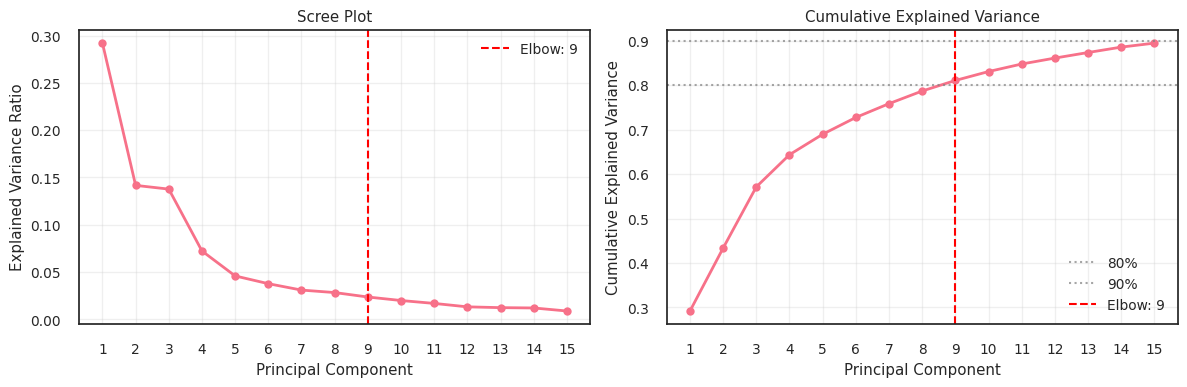

Optimal components: 9
Explained variance at elbow: 81.1%


In [27]:
# Fit PCA with all components
feature_cols = [c for c in norm_vars_feat_select_int_df.columns if "Metadata" not in c]

pca_full = PCA()
pca_full.fit(norm_vars_feat_select_int_df.select(feature_cols).to_numpy())

# Calculate variances
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

from kneed import KneeLocator
# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee

# explained_var_thres = 0.6
# cumvar = np.cumsum(pca_full.explained_variance_ratio_)
# optimal_components = np.argmax(cumvar >= explained_var_thres) + 1

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

# Apply optimal PCA
pca = PCA(n_components=optimal_components)
data_pca = pca.fit_transform(norm_vars_feat_select_int_df.select(feature_cols).to_numpy())

In [28]:
# UMAP plot
reducer = umap.UMAP(n_components=2, random_state=42) ## metric='cosine', 
umap_embedding = reducer.fit_transform(data_pca)

### 3.2 Louvain Clustering

In [29]:
# Generate k-NN graph
k = 15  # adjust based on testing
nbrs = NearestNeighbors(n_neighbors=k, metric='cosine')
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# Build unweighted graph
G = nx.Graph()
for i in range(len(data_pca)):
    for j in indices[i][1:]:  # skip self
        G.add_edge(i, j)

# Louvain clustering
cluster_dict = community_louvain.best_partition(G) # , resolution=2

In [30]:
dr_res_df = pd.DataFrame(
    data_pca,
    columns=[f"PC{i}" for i in range(1, data_pca.shape[1]+1)]
)
dr_res_df = pd.concat([
    dr_res_df,
    pd.DataFrame(umap_embedding, 
                 columns=["UMAP1", "UMAP2"])
    ],
    axis=1
)

dr_res_df["cluster"] = dr_res_df.index.map(cluster_dict)
dr_res_df["Metadata_mislocalized"] = norm_vars_feat_select_int_df["Metadata_mislocalized"]
dr_res_df.index = norm_vars_feat_select_int_df["Metadata_gene_allele"]

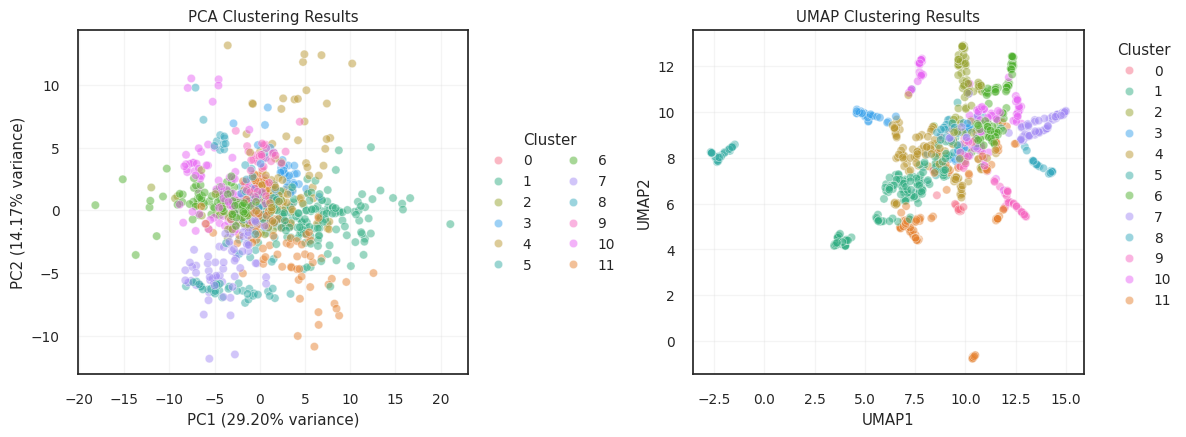

In [31]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["cluster"].unique())}

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=2)

# PCA plot
sns.scatterplot(
    dr_res_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5
)

# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')
ax[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Cluster")

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.3)
plt.tight_layout()
plt.show()

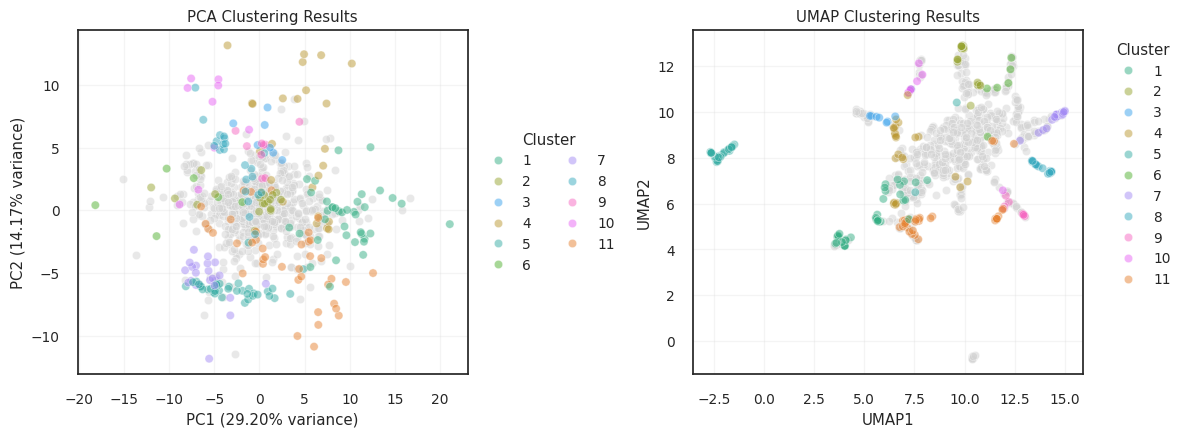

In [32]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["cluster"].unique())}

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df[~dr_res_df["Metadata_mislocalized"]],
    x="PC1",
    y="PC2",
    # hue="cluster",
    color="lightgrey",
    ax=ax[0],
    alpha=.5,
    legend=False
)
sns.scatterplot(
    dr_res_df[dr_res_df["Metadata_mislocalized"]],
    x="PC1",
    y="PC2",
    hue="cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=2)

# PCA plot
sns.scatterplot(
    dr_res_df[~dr_res_df["Metadata_mislocalized"]],
    x="UMAP1",
    y="UMAP2",
    # hue="cluster",
    color="lightgrey",
    ax=ax[1],
    alpha=.5,
    legend=False
)
sns.scatterplot(
    dr_res_df[dr_res_df["Metadata_mislocalized"]],
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5
)

# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')
ax[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Cluster")

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.tight_layout()
plt.show()

In [38]:
# dr_res_df[dr_res_df["UMAP2"]<0]

In [39]:
# dr_res_df[dr_res_df["cluster"]==11]

In [40]:
# dr_res_df[dr_res_df["UMAP1"]<0]

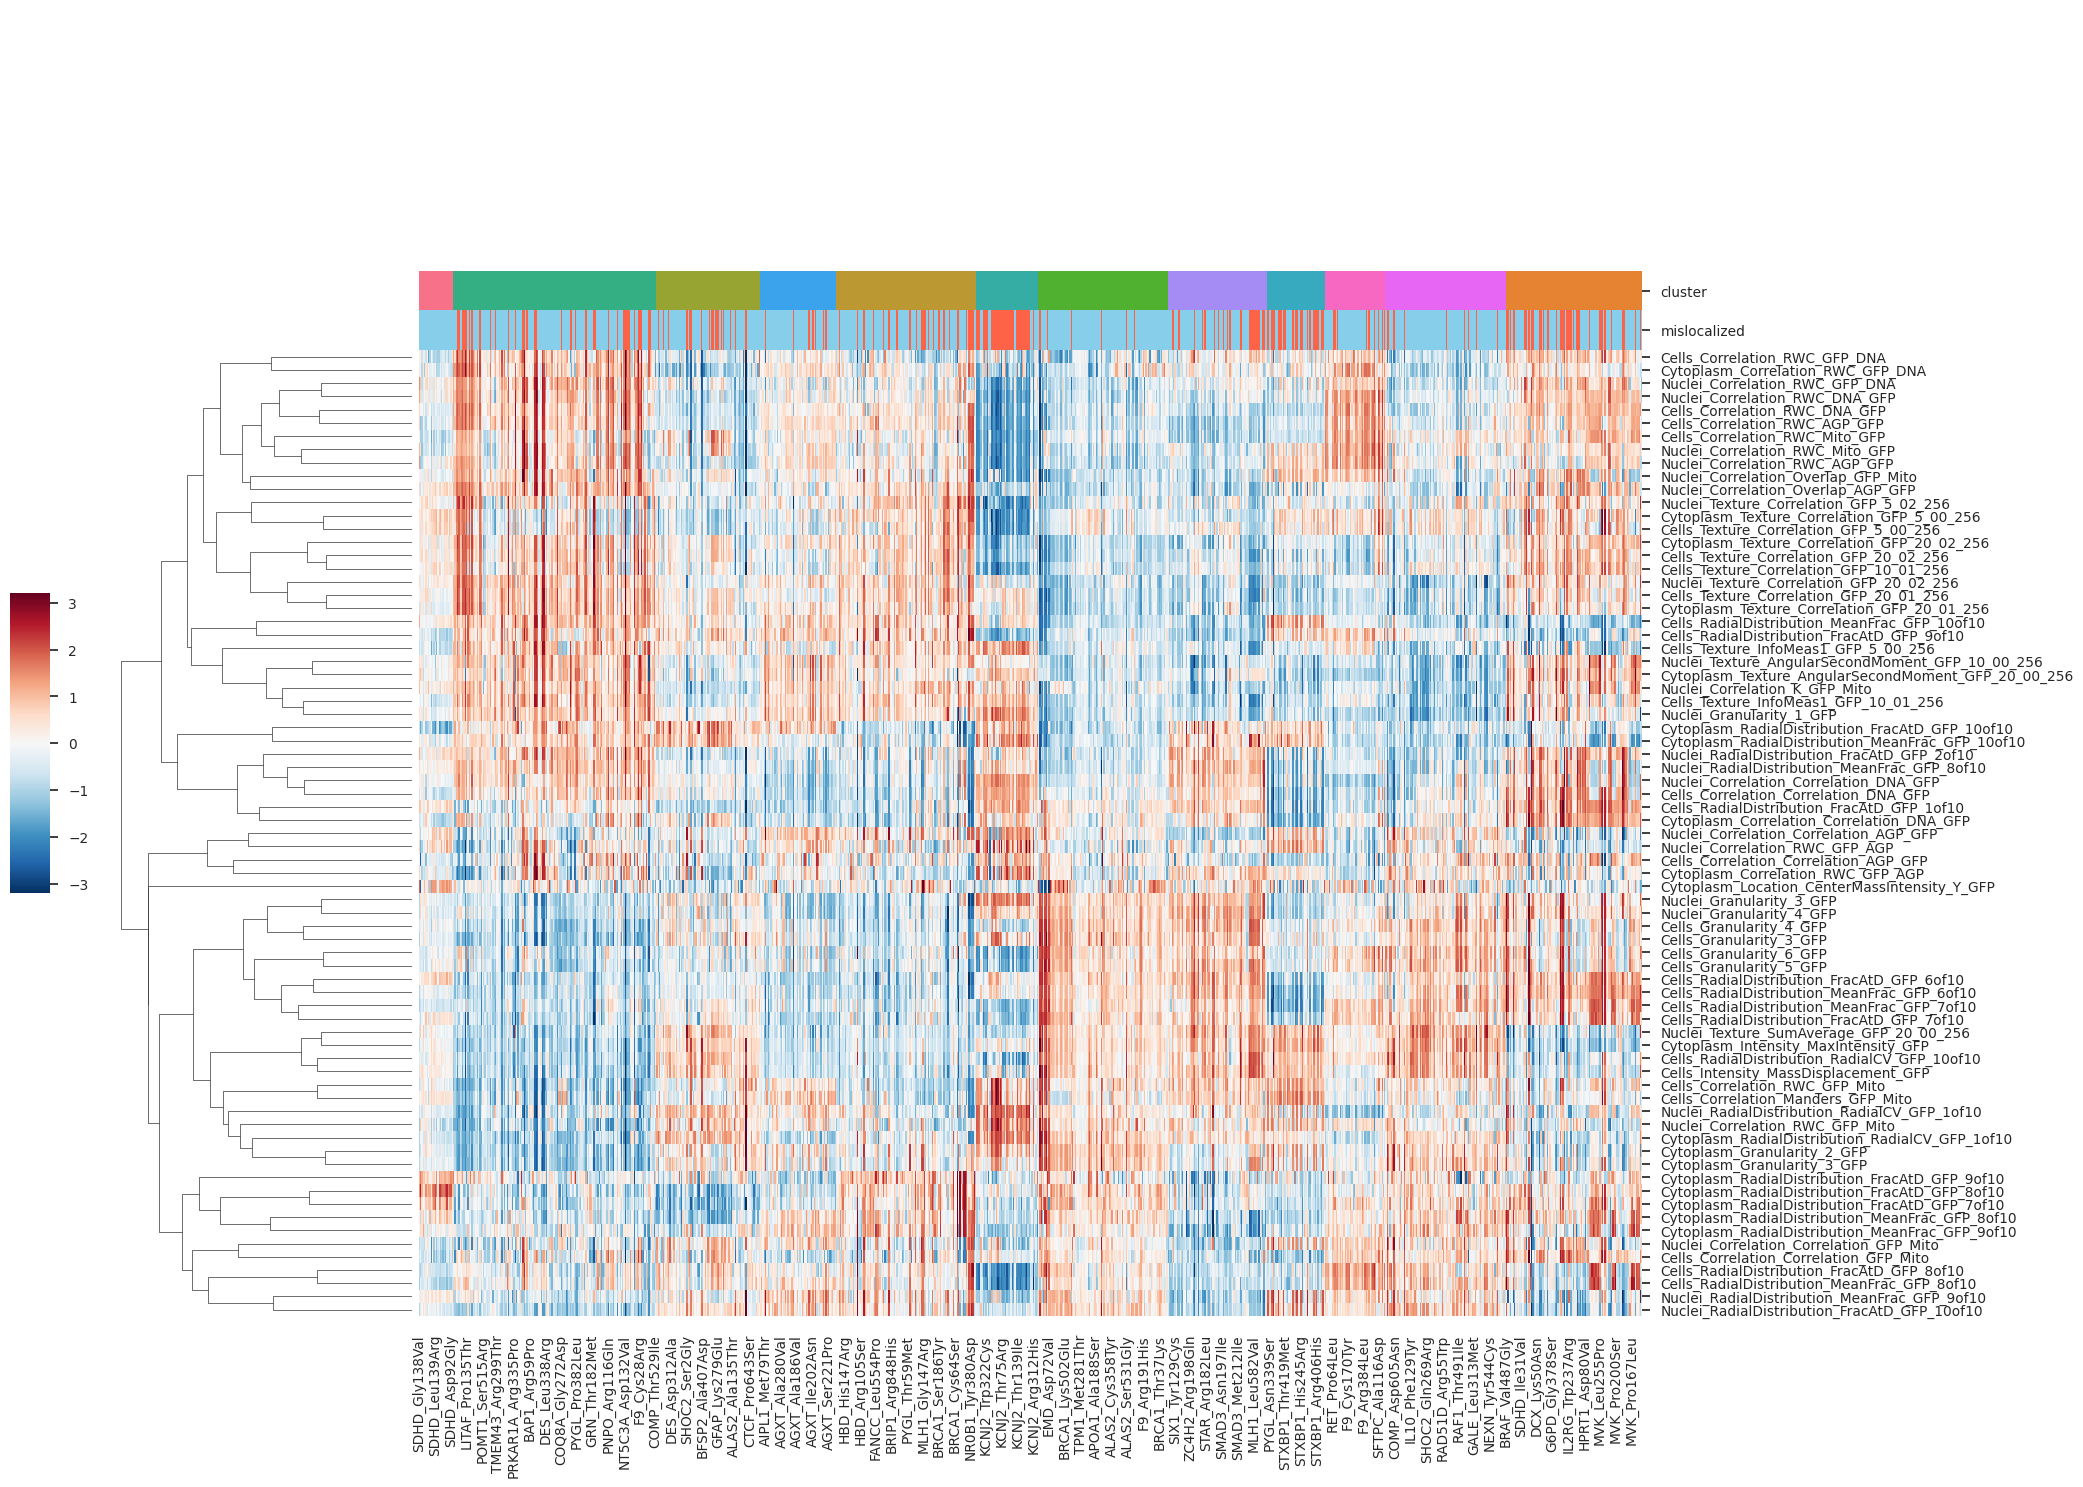

In [34]:
# Create dataframe with cluster labels
data_scaled_df = pd.DataFrame(norm_vars_feat_select_int_df.select(feature_cols).to_numpy(), 
                              index=norm_vars_feat_select_int_df["Metadata_gene_allele"], 
                              columns=feature_cols)

df_clustered = data_scaled_df.copy()
df_clustered['cluster'] = dr_res_df["cluster"]
df_clustered['mislocalized'] = dr_res_df["Metadata_mislocalized"].to_numpy()

# Sort by cluster for better visualization
df_sorted = df_clustered.sort_values('cluster')
cluster_labels = df_sorted['cluster'].values
mislocalized_sorted = df_sorted['mislocalized'].values

# Create cluster colormap
cluster_colors = color_map

data_for_heatmap = df_sorted.drop(['cluster', 'mislocalized'], axis=1)
row_colors = pd.DataFrame(
   {
       "cluster": [cluster_colors[c] for c in cluster_labels],
       "mislocalized": ["tomato" if x else "skyblue" for x in mislocalized_sorted]
   },
   index = df_sorted.index
)

sns.clustermap(data_for_heatmap.T, 
              row_cluster=True, 
              col_cluster=False,
              col_colors=row_colors,
              cbar_pos=(-0.04, 0.4, 0.02, 0.2),
              cmap='RdBu_r', 
              center=0,
              yticklabels=1,
              figsize=(20, 15))
plt.show()

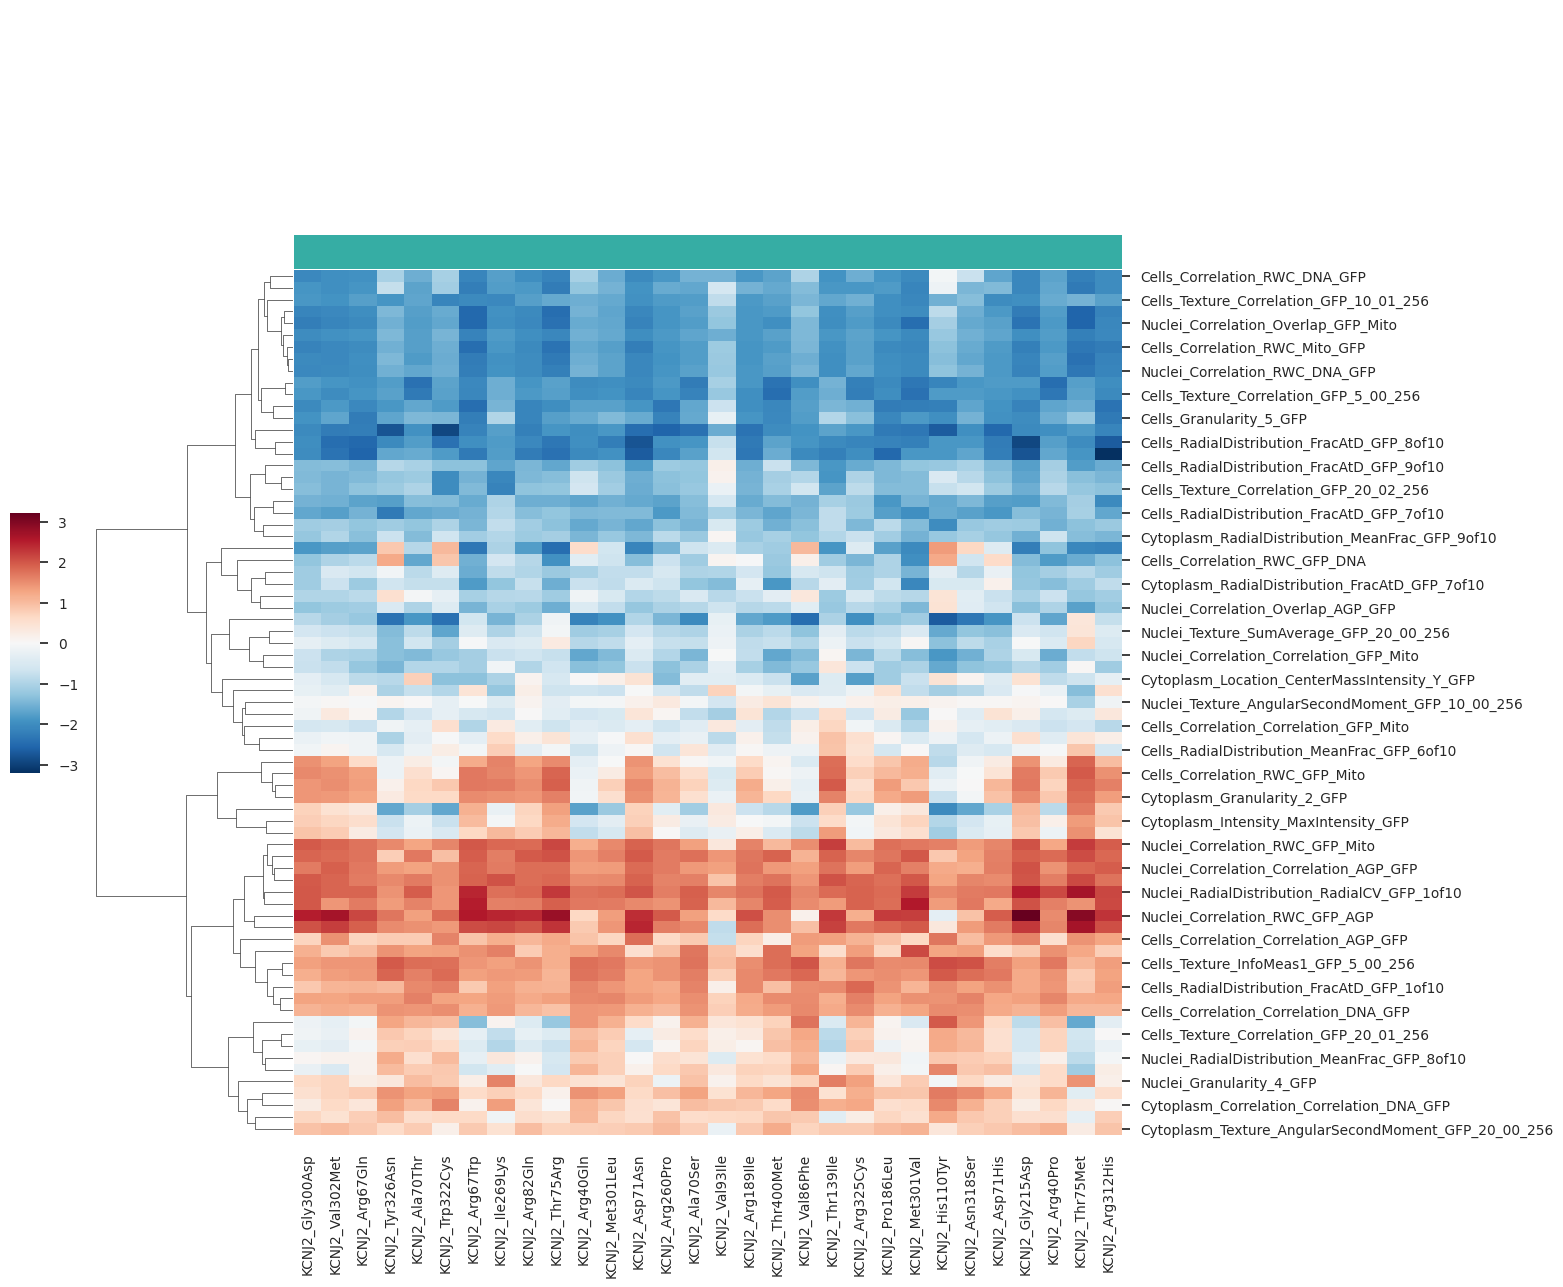

In [41]:
cluster_labels_kcnj2 = df_sorted.loc[[var for var in data_for_heatmap.index if "KCNJ2" in var],:]['cluster'].values
data_for_heatmap_kcnj2 = df_sorted.loc[[var for var in data_for_heatmap.index if "KCNJ2" in var],:].drop('cluster', axis=1)
row_colors_kcnj2 = [cluster_colors[c] for c in cluster_labels_kcnj2]

sns.clustermap(data_for_heatmap_kcnj2[feature_cols].T, 
               row_cluster=True, 
               col_cluster=False,
               col_colors=row_colors_kcnj2,
               cbar_pos=(-0.04, 0.4, 0.02, 0.2),
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

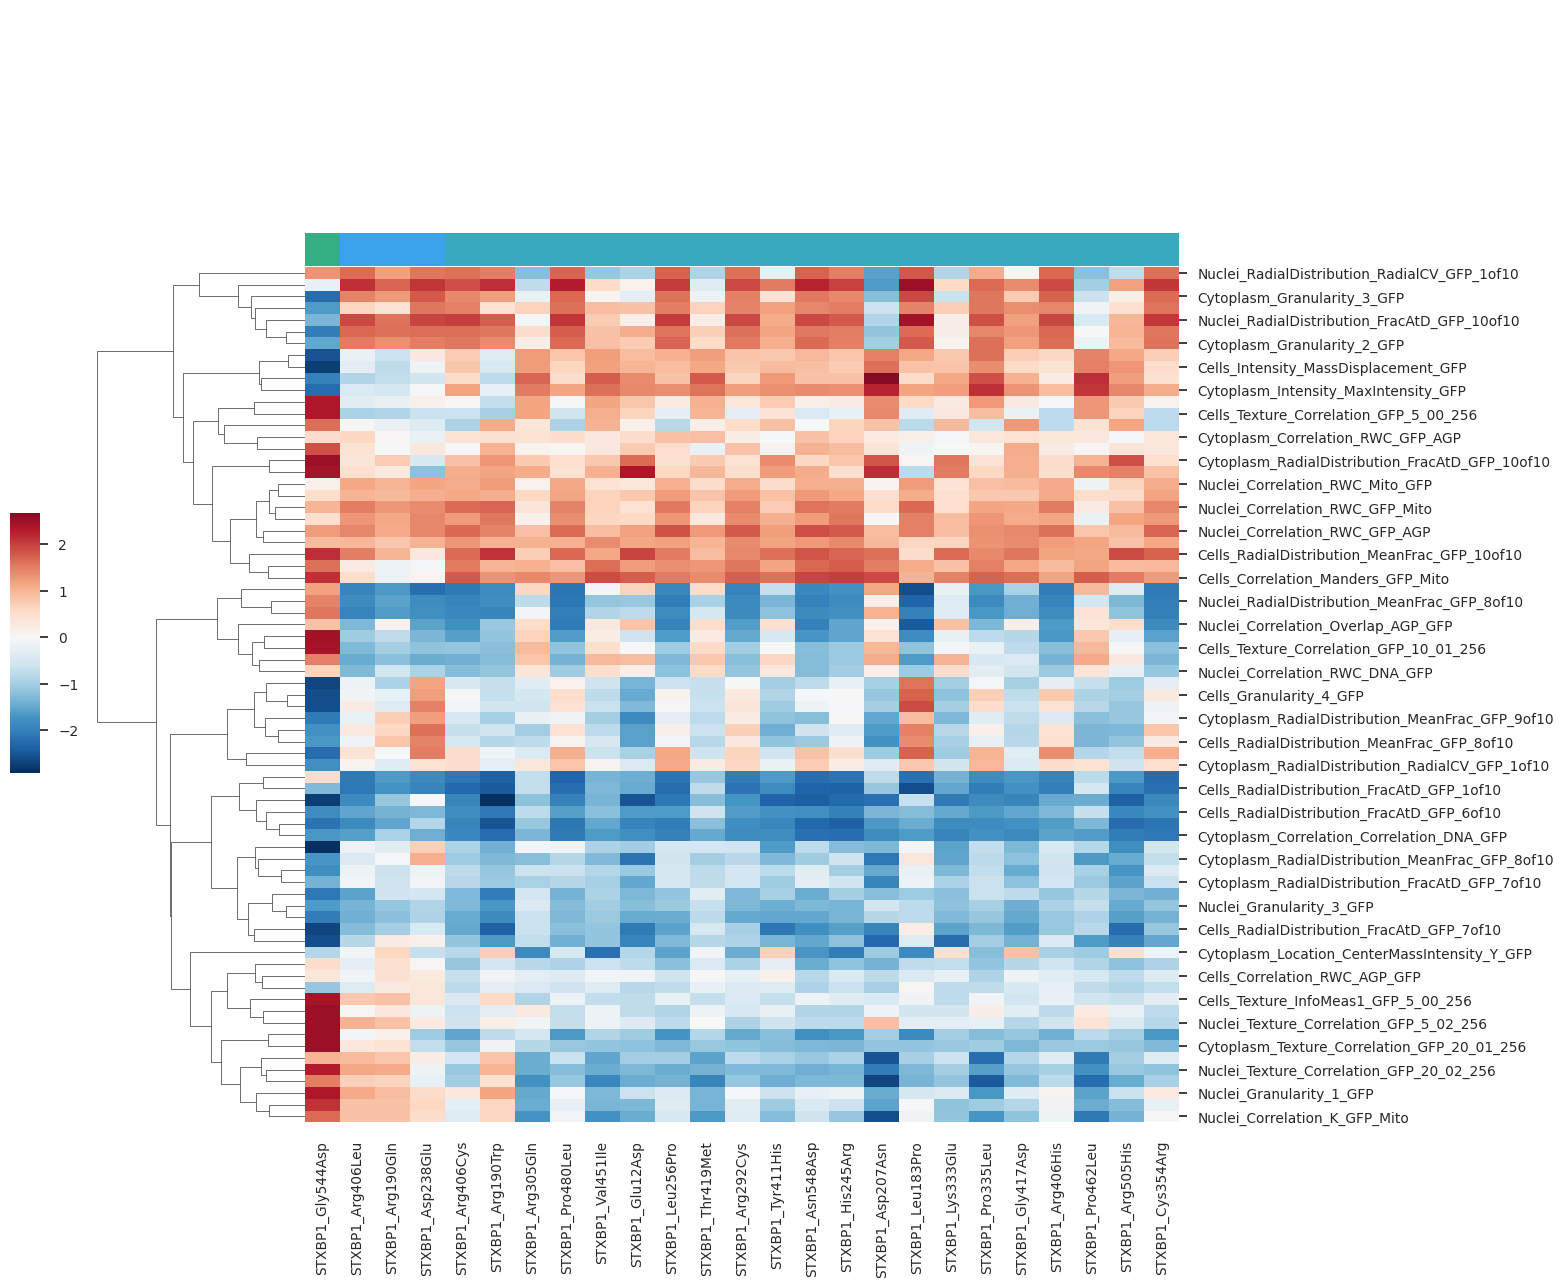

In [42]:
cluster_labels_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "STXBP1" in var],:]['cluster'].values
data_for_heatmap_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "STXBP1" in var],:].drop('cluster', axis=1)
row_colors_stx = [cluster_colors[c] for c in cluster_labels_stx]
sns.clustermap(data_for_heatmap_stx[feature_cols].T, 
               # z_score=0,
               row_cluster=True, 
               col_cluster=False,
               col_colors=row_colors_stx,
               cbar_pos=(-0.04, 0.4, 0.02, 0.2),
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

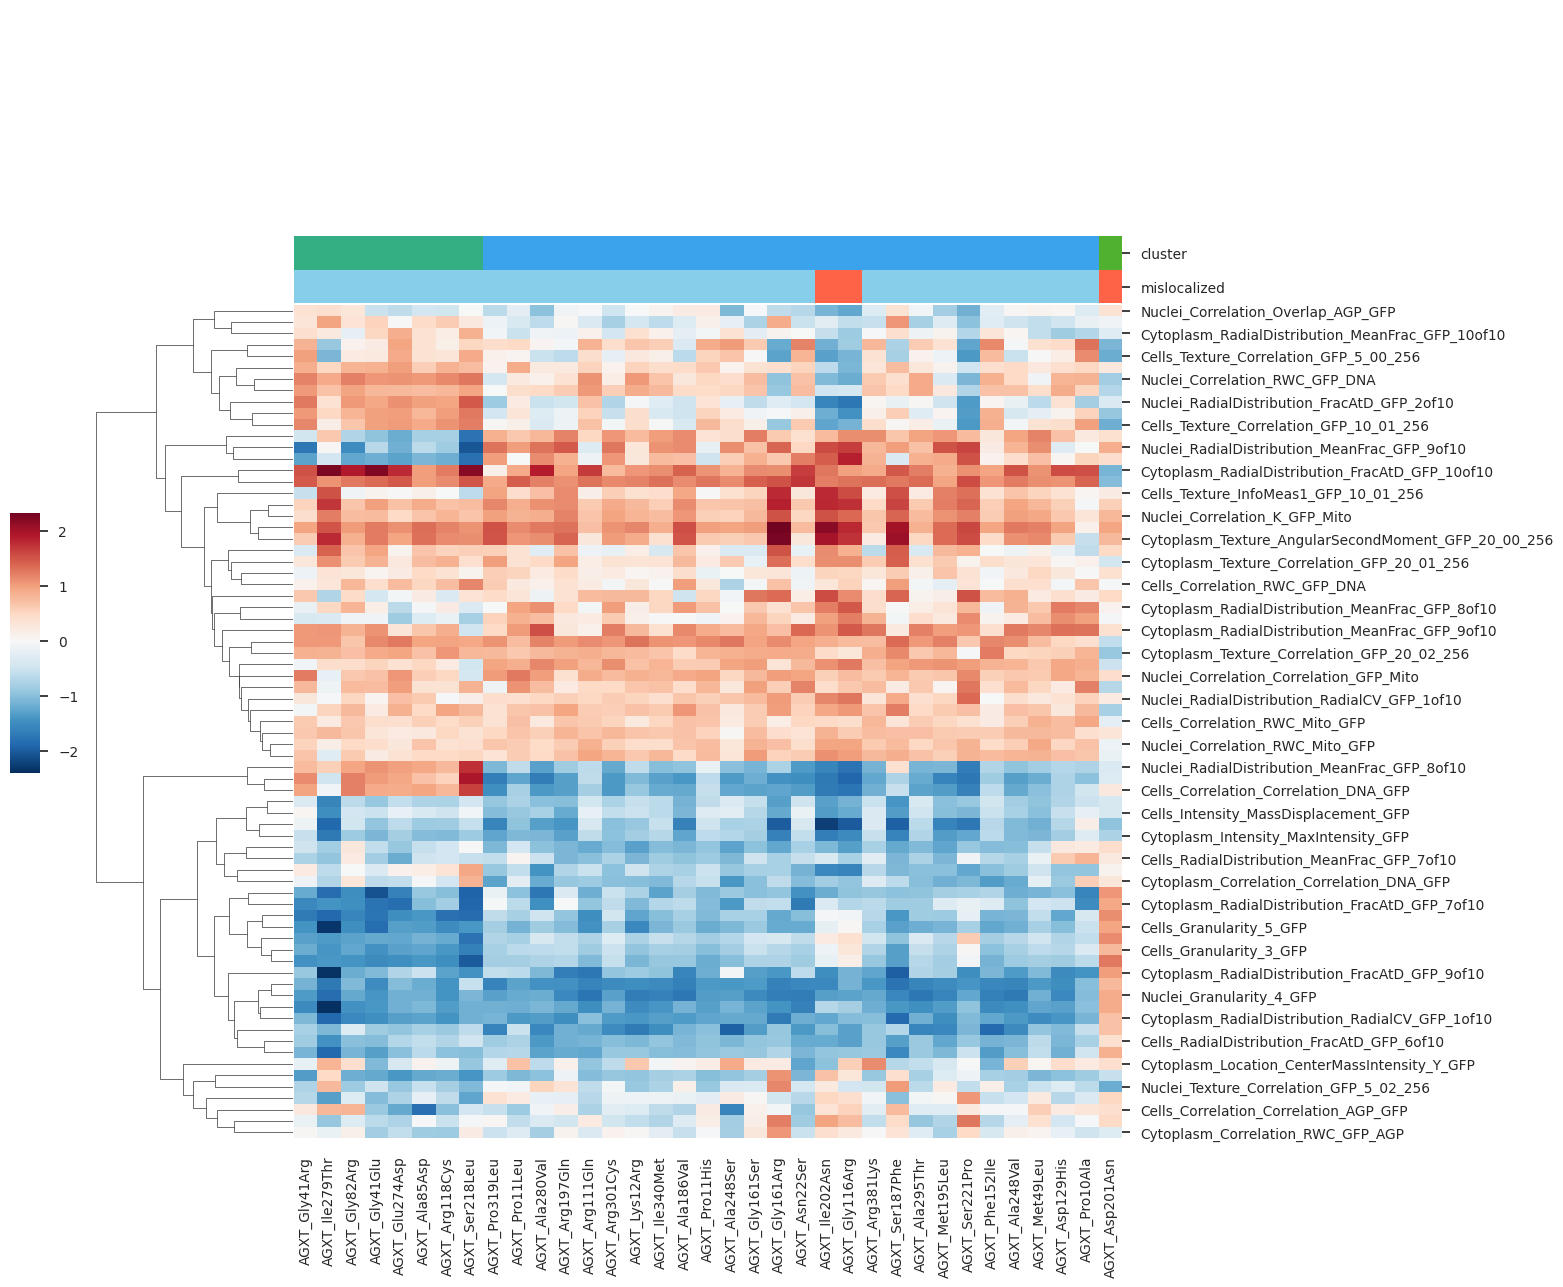

In [100]:
cluster_labels_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "AGXT" in var],:]['cluster'].values
mislocalized_sorted_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "AGXT" in var],:]['mislocalized'].values
data_for_heatmap_stx = df_sorted.loc[[var for var in data_for_heatmap.index if "AGXT" in var],:].drop('cluster', axis=1)
row_colors_stx = pd.DataFrame(
   {
       "cluster": [cluster_colors[c] for c in cluster_labels_stx],
       "mislocalized": ["tomato" if x else "skyblue" for x in mislocalized_sorted_stx]
   },
   index = df_sorted.loc[[var for var in data_for_heatmap.index if "AGXT" in var],:].index
)
sns.clustermap(data_for_heatmap_stx[feature_cols].T, 
               # z_score=0,
               row_cluster=True, 
               col_cluster=False,
               col_colors=row_colors_stx,
               cbar_pos=(-0.04, 0.4, 0.02, 0.2),
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

## 4. Cluster Analysis

In [97]:
df_clustered.loc[[idx for idx in df_clustered.index if "AGXT" in idx],:].sort_values(["mislocalized","cluster"], ascending=False)[["cluster","mislocalized"]]#.head()#[df_clustered["mislocalized"]]

,cluster,mislocalized
AGXT_Asp201Asn,6,True
AGXT_Gly116Arg,3,True
AGXT_Ile202Asn,3,True
AGXT_Pro319Leu,3,False
AGXT_Ala280Val,3,False
AGXT_Ala186Val,3,False
AGXT_Ala248Ser,3,False
AGXT_Ile340Met,3,False
AGXT_Lys12Arg,3,False
AGXT_Arg111Gln,3,False


### 4.1 Map clustering with Structural Scores

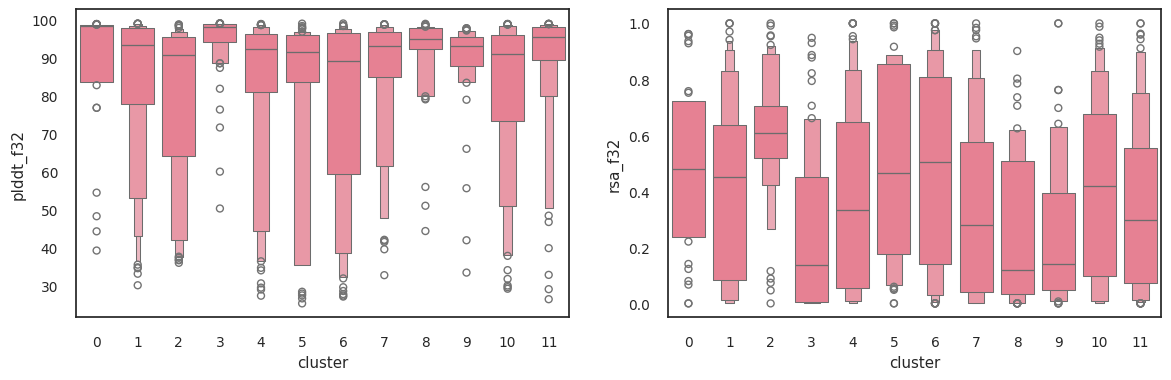

In [43]:
map_clus_df = pl.DataFrame(df_clustered.reset_index()).join(
    imaging_summary_clinvar,
    left_on="index",
    right_on="gene_allele"
).with_columns(
    pl.col("index").str.split('_').list.get(0).alias("gene")
).join(
    ref_var_cell_all_prof_df.filter(
        pl.col("Metadata_hpa_main_loc").is_not_null()
    ).unique("Metadata_gene_allele").select(
        pl.col("Metadata_gene_allele", "Metadata_hpa_main_loc", "Metadata_final_loc")
    ),
    left_on="gene",
    right_on="Metadata_gene_allele",
    how="left"
)

fig, ax = plt.subplots(1,2,figsize=(14,4))
sns.boxenplot(
    data=map_clus_df.to_pandas(),
    x="cluster",
    y="plddt_f32",
    ax=ax[0]
)
sns.boxenplot(
    data=map_clus_df.to_pandas(),
    x="cluster",
    y="rsa_f32",
    ax=ax[1]
)
plt.show()

In [44]:
map_clus_df = pl.DataFrame(df_clustered.reset_index()).join(
    imaging_summary_clinvar,
    left_on="index",
    right_on="gene_allele"
).with_columns(
    pl.col("index").str.split('_').list.get(0).alias("gene")
)

In [45]:
for cluster in map_clus_df["cluster"].unique():
    print(cluster)
    with pl.Config(set_tbl_rows=20):
        print(
            map_clus_df.join(
                ref_var_cell_all_prof_df.unique(subset=["Metadata_gene_allele","Metadata_hpa_main_loc","Metadata_final_loc"]),
                left_on="gene",
                right_on="Metadata_gene_allele"
            ).filter(
                (pl.col("cluster")==cluster) & (pl.col("Metadata_hpa_main_loc")!="Uncertain")
            ).unique(subset=["gene", "Metadata_hpa_main_loc", "Metadata_final_loc"]).select(
                ["gene", "Metadata_hpa_main_loc"]
            ).sort("Metadata_hpa_main_loc")
        )

0
shape: (8, 2)
┌────────┬─────────────────────────────────┐
│ gene   ┆ Metadata_hpa_main_loc           │
│ ---    ┆ ---                             │
│ str    ┆ str                             │
╞════════╪═════════════════════════════════╡
│ NEXN   ┆ Actin filaments;Plasma membran… │
│ UBQLN2 ┆ Cytosol                         │
│ PYGL   ┆ Cytosol;Plasma membrane         │
│ BRCA1  ┆ Nuclear bodies;Nucleoplasm      │
│ AIPL1  ┆ Nuclear speckles                │
│ SIX1   ┆ Nucleoplasm                     │
│ THAP1  ┆ Nucleoplasm                     │
│ CFP    ┆ Vesicles                        │
└────────┴─────────────────────────────────┘
1
shape: (38, 2)
┌─────────┬────────────────────────────────┐
│ gene    ┆ Metadata_hpa_main_loc          │
│ ---     ┆ ---                            │
│ str     ┆ str                            │
╞═════════╪════════════════════════════════╡
│ TPM1    ┆ Actin filaments                │
│ NCF2    ┆ Cytosol                        │
│ PRKAR1A ┆ Cytosol   

In [46]:
from scipy.stats import ks_2samp, chi2, mannwhitneyu
from statsmodels.stats.multitest import multipletests
import warnings

def analyze_louvain_clusters_standard(data_original, clusters, feature_names=None, 
                                      significance_threshold=0.001, top_n=0, 
                                      sort_by='effect_size', test_method='ks'):
    """
    Standard analysis without permutation correction (for comparison)
    """
    # Convert to numpy array if DataFrame
    if isinstance(data_original, pd.DataFrame):
        data_array = data_original.values
        if feature_names is None:
            feature_names = data_original.columns.tolist()
    else:
        data_array = data_original
        if feature_names is None:
            feature_names = [f'Feature_{i}' for i in range(data_array.shape[1])]
    
    # Convert clusters to dict format if needed
    if not isinstance(clusters, dict):
        clusters = {i: cluster_id for i, cluster_id in enumerate(clusters)}
    
    # Standardize data
    data_scaled = data_array
    
    results = {}
    cluster_ids = sorted(set(clusters.values()))
    
    for cluster_id in cluster_ids:
        # Get sample indices for this cluster vs others
        cluster_sample_indices = [i for i, c in clusters.items() if c == cluster_id]
        other_sample_indices = [i for i, c in clusters.items() if c != cluster_id]
        
        if len(cluster_sample_indices) < 5 or len(other_sample_indices) < 5:
            print(f"Warning: Cluster {cluster_id} has too few samples for reliable testing")
            continue
            
        # Extract data for samples in this cluster vs others
        cluster_data = data_scaled[cluster_sample_indices, :]
        other_data = data_scaled[other_sample_indices, :]
        
        # Perform standard statistical tests
        p_values = []
        statistics = []
        effect_sizes = []
        
        for feature_idx in range(data_scaled.shape[1]):
            cluster_feature = cluster_data[:, feature_idx]
            other_feature = other_data[:, feature_idx]
            
            if test_method == 'ks':
                stat, p_val = ks_2samp(cluster_feature, other_feature)
            elif test_method == 'mw':
                stat, p_val = mannwhitneyu(cluster_feature, other_feature, alternative='two-sided')
            else:
                raise ValueError(f"Unknown test method: {test_method}")
            
            effect_size = np.median(cluster_feature) - np.median(other_feature)
            
            p_values.append(p_val)
            statistics.append(stat)
            effect_sizes.append(effect_size)
        
        # Multiple testing correction
        rejected, p_corrected, _, _ = multipletests(p_values, method='bonferroni')
        
        # Create results dataframe for this cluster
        cluster_results = pd.DataFrame({
            'feature': feature_names,
            'test_statistic': statistics,
            'p_value': p_values,
            'p_corrected': p_corrected,
            'significant': rejected,
            'effect_size': effect_sizes,
            'abs_effect_size': np.abs(effect_sizes),
            'cluster_median': np.median(cluster_data, axis=0),
            'other_median': np.median(other_data, axis=0),
            'cluster_size': len(cluster_sample_indices),
            'other_size': len(other_sample_indices)
        })
        
        # Apply filtering and sorting
        if top_n == 0:
            # Return all significant features
            filtered_results = cluster_results[cluster_results['p_corrected'] < significance_threshold]
        else:
            # Return top_n features regardless of significance
            filtered_results = cluster_results.copy()
        
        # Sort based on chosen method
        if sort_by == 'effect_size':
            filtered_results = filtered_results.sort_values('abs_effect_size', ascending=False)
        elif sort_by == 'p_value':
            filtered_results = filtered_results.sort_values('p_corrected', ascending=True)
        elif sort_by == 'combined':
            filtered_results = filtered_results.sort_values(
                ['significant', 'abs_effect_size'], 
                ascending=[False, False]
            )
        
        # Apply top_n limit if specified
        if top_n > 0:
            filtered_results = filtered_results.head(top_n)
        
        results[f'Cluster_{cluster_id}'] = filtered_results
    
    return results


def display_results_enhanced(cluster_results, clusters, method_name="Analysis"):
    """Enhanced display function with more detailed statistics"""
    print(f"=== {method_name} Results ===")
    
    if isinstance(clusters, dict):
        cluster_counts = {}
        for cluster_id in set(clusters.values()):
            cluster_counts[cluster_id] = sum(1 for c in clusters.values() if c == cluster_id)
    else:
        unique, counts = np.unique(clusters, return_counts=True)
        cluster_counts = dict(zip(unique, counts))
    
    for cluster_name, df in cluster_results.items():
        cluster_id = cluster_name.split('_')[1]
        n_samples = cluster_counts.get(int(cluster_id), 0) if cluster_id.isdigit() else 0
        n_features = len(df)
        n_significant = (df['p_corrected'] < 0.001).sum()
        
        print(f"\n{cluster_name} (n={n_samples}):")
        print(f"Features analyzed: {n_features}, Significant (p<0.001): {n_significant}")
        
        if n_features > 0:
            print(f"{'Feature':<20} {'Test Stat':<10} {'P-value':<12} {'P-corrected':<12} {'Effect Size':<12} {'Sig':<5}")
            print("-" * 75)
            
            for idx, row in df.head(10).iterrows():  # Show top 10
                sig_marker = "***" if row['p_corrected'] < 0.001 else "**" if row['p_corrected'] < 0.01 else "*" if row['p_corrected'] < 0.05 else ""
                print(f"{row['feature']:<20} {row['test_statistic']:<10.3f} {row['p_value']:<12.2e} {row['p_corrected']:<12.2e} {row['effect_size']:<12.3f} {sig_marker:<5}")
        else:
            print("  No features found")

# Example usage:
# Standard analysis (without permutation correction):
results_standard = analyze_louvain_clusters_standard(
    norm_vars_feat_select_int_df.select(feature_cols).to_numpy(), 
    dr_res_df["cluster"], 
    feature_names=feature_cols,
    significance_threshold=0.001,
    top_n=20,
    sort_by='combined'
)
display_results_enhanced(results_standard, cluster_dict, "Standard Analysis")

=== Standard Analysis Results ===

Cluster_0 (n=26):
Features analyzed: 20, Significant (p<0.001): 15
Feature              Test Stat  P-value      P-corrected  Effect Size  Sig  
---------------------------------------------------------------------------
Cytoplasm_RadialDistribution_FracAtD_GFP_8of10 0.698      8.86e-13     6.47e-11     1.676        ***  
Cytoplasm_RadialDistribution_FracAtD_GFP_10of10 0.597      4.12e-09     3.01e-07     -1.246       ***  
Cytoplasm_Location_CenterMassIntensity_Y_GFP 0.540      2.03e-07     1.48e-05     1.175        ***  
Cytoplasm_RadialDistribution_FracAtD_GFP_9of10 0.558      6.20e-08     4.53e-06     1.017        ***  
Cells_RadialDistribution_MeanFrac_GFP_8of10 0.584      1.04e-08     7.58e-07     -0.940       ***  
Cytoplasm_RadialDistribution_FracAtD_GFP_7of10 0.475      9.37e-06     6.84e-04     0.882        ***  
Cells_Correlation_RWC_Mito_GFP 0.500      2.37e-06     1.73e-04     -0.823       ***  
Cells_RadialDistribution_FracAtD_GFP_9of10 0

In [48]:
# fig, ax = plt.subplots(1,2,figsize=(10,5))
# sns.swarmplot(
#     data=map_clus_df.filter(
#         pl.col("index").str.contains("STXBP1_")
#     ).to_pandas(),
#     x="cluster",
#     y="rsa_f32",
#     ax=ax[0]
# )
# sns.swarmplot(
#     data=map_clus_df.filter(
#         pl.col("index").str.contains("STXBP1_")
#     ).to_pandas(),
#     x="cluster",
#     y="plddt_f32",
#     ax=ax[1]
# )
# plt.show()

2. Permutation-Corrected Analysis:
Selected 43 unique features across 12 clusters
Total feature-cluster pairs: 60


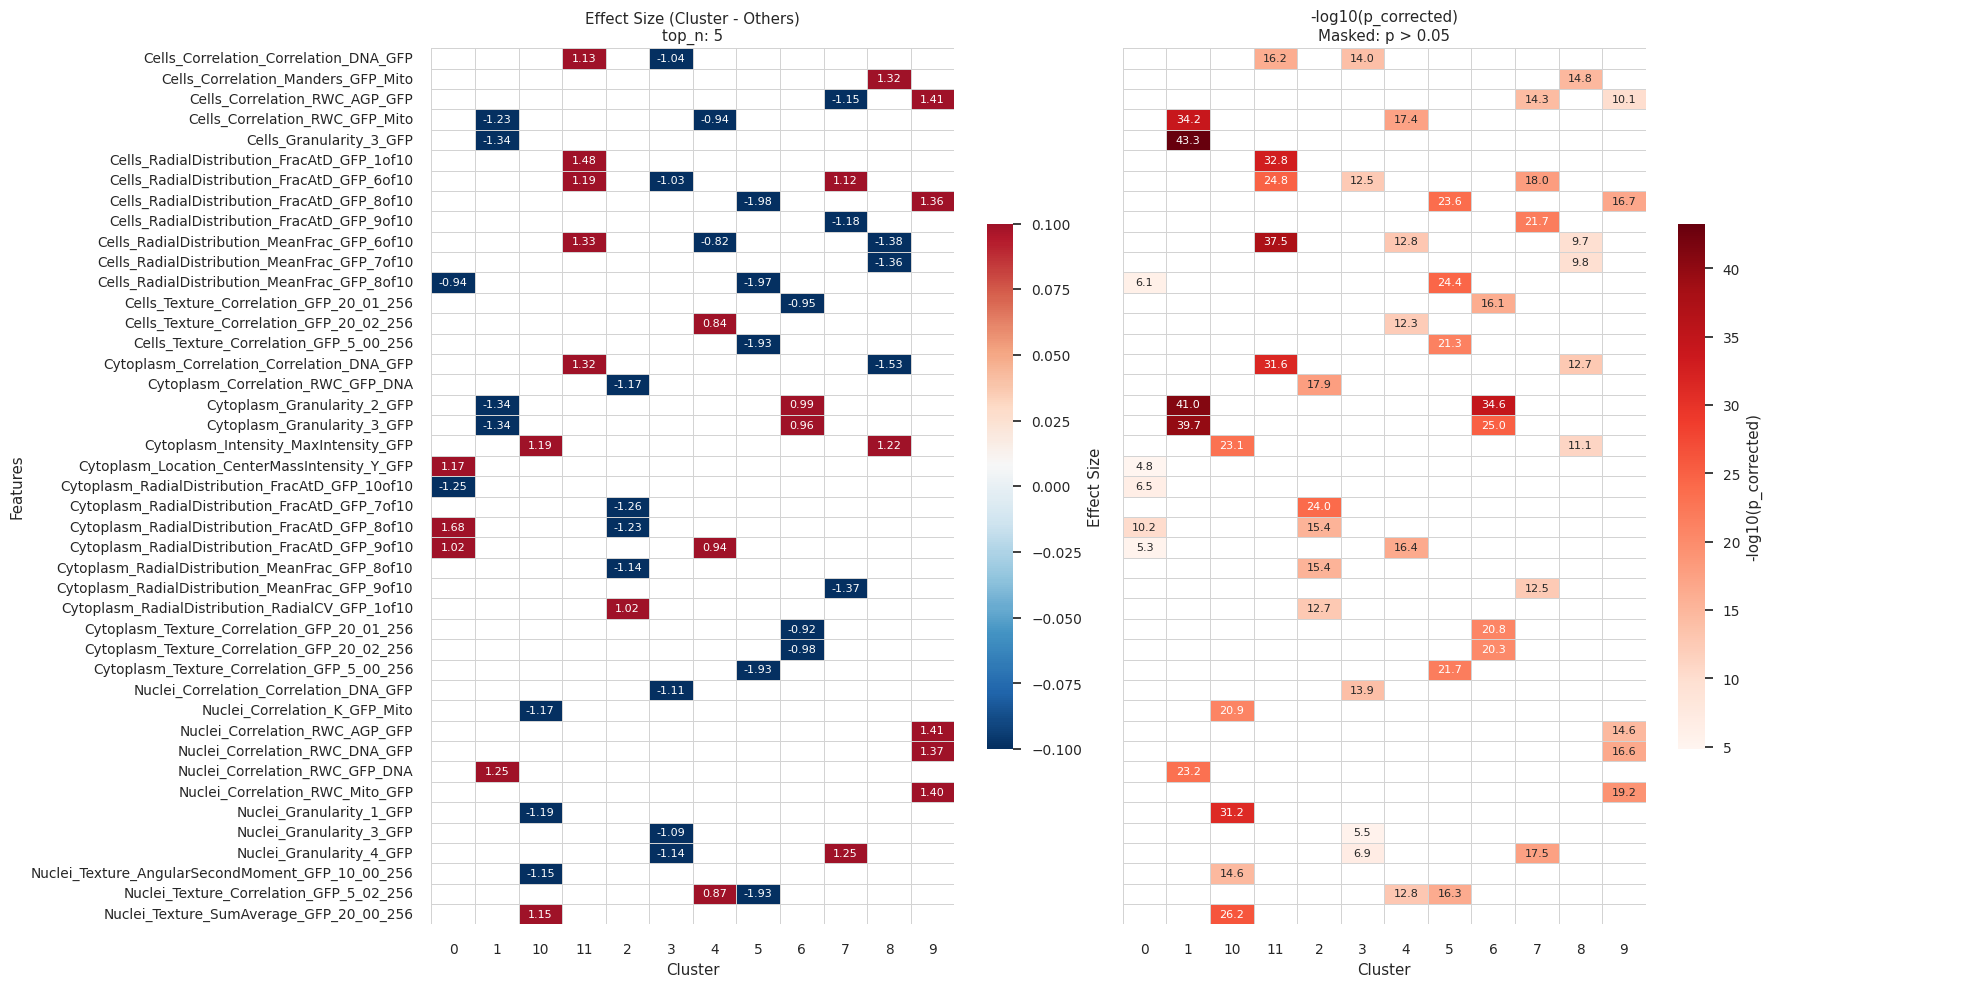

In [49]:
from matplotlib.colors import TwoSlopeNorm
import warnings

def plot_significant_features_heatmap(cluster_results, 
                                      selection_method='p_threshold', 
                                      top_n=5, 
                                      p_threshold=0.001,
                                      min_effect_size=0.0,
                                      max_features_per_cluster=20,
                                      figsize=(16, 10),
                                      show_values=True,
                                      save_path=None,
                                      cluster_order=None,
                                      feature_clustering=True):
    """
    Plot heatmap of significant differential features per cluster with flexible selection criteria
    
    Parameters:
    -----------
    cluster_results: dict, results from analyze_louvain_clusters_* functions
    selection_method: str, 'top_n', 'p_threshold', or 'combined'
        - 'top_n': Select top N features per cluster by effect size
        - 'p_threshold': Select features below p-value threshold
        - 'combined': Select top N features that also meet p-value threshold
    top_n: int, number of top features per cluster (when selection_method includes top_n)
    p_threshold: float, p-value threshold for feature selection
    min_effect_size: float, minimum absolute effect size to include
    max_features_per_cluster: int, maximum features per cluster to prevent overcrowding
    figsize: tuple, figure size
    show_values: bool, whether to show values in heatmap cells
    save_path: str, path to save figure (optional)
    cluster_order: list, custom order for clusters (optional)
    feature_clustering: bool, whether to cluster features hierarchically
    
    Returns:
    --------
    fig: matplotlib figure object
    selected_features: dict, features selected per cluster
    """
    
    if not cluster_results:
        print("No cluster results provided")
        return None, None
    
    # Extract significant features based on selection method
    selected_features_data = []
    selected_features = {}
    
    for cluster_name, df in cluster_results.items():
        cluster_id = cluster_name.split('_')[1]
        
        # Apply selection criteria
        if selection_method == 'top_n':
            # Select top N features by absolute effect size
            filtered_df = df.head(min(top_n, len(df)))
            
        elif selection_method == 'p_threshold':
            # Select features below p-value threshold
            filtered_df = df[df['p_corrected'] < p_threshold]
            
        elif selection_method == 'combined':
            # Select top N features that also meet p-value threshold
            significant_df = df[df['p_corrected'] < p_threshold]
            filtered_df = significant_df.head(min(top_n, len(significant_df)))
            
        else:
            raise ValueError("selection_method must be 'top_n', 'p_threshold', or 'combined'")
        
        # Apply additional filters
        if min_effect_size > 0:
            filtered_df = filtered_df[filtered_df['abs_effect_size'] >= min_effect_size]
        
        # Limit maximum features per cluster
        if len(filtered_df) > max_features_per_cluster:
            filtered_df = filtered_df.head(max_features_per_cluster)
            print(f"Warning: Cluster {cluster_id} truncated to {max_features_per_cluster} features")
        
        # Store selected features for this cluster
        selected_features[cluster_id] = filtered_df['feature'].tolist()
        
        # Add to data for heatmap
        for _, row in filtered_df.iterrows():
            selected_features_data.append({
                'cluster': cluster_id,
                'feature': row['feature'],
                'effect_size': row['effect_size'],
                'abs_effect_size': row['abs_effect_size'],
                'neg_log_p': -np.log10(max(row['p_corrected'], 1e-300)),
                'p_corrected': row['p_corrected'],
                'test_statistic': row['test_statistic']
            })
    
    if not selected_features_data:
        print(f"No features found with selection_method='{selection_method}', "
              f"top_n={top_n}, p_threshold={p_threshold}")
        return None, None
    
    # Create DataFrame and pivot tables
    heatmap_df = pd.DataFrame(selected_features_data)
    
    # Get all unique features and clusters
    all_features = heatmap_df['feature'].unique()
    all_clusters = sorted(heatmap_df['cluster'].unique()) if cluster_order is None else cluster_order
    
    print(f"Selected {len(all_features)} unique features across {len(all_clusters)} clusters")
    print(f"Total feature-cluster pairs: {len(heatmap_df)}")
    
    # Create pivot tables (fill missing values with 0)
    pivot_effect = heatmap_df.pivot_table(
        index='feature', columns='cluster', values='effect_size', fill_value=0
    )[all_clusters]  # Ensure column order
    
    pivot_significance = heatmap_df.pivot_table(
        index='feature', columns='cluster', values='neg_log_p', fill_value=0
    )[all_clusters]
    
    # Optional: Cluster features hierarchically
    if feature_clustering and len(all_features) > 1:
        from scipy.cluster.hierarchy import linkage, dendrogram
        from scipy.spatial.distance import pdist
        
        # Calculate distance matrix for features based on effect sizes
        feature_distances = pdist(pivot_effect.values, metric='euclidean')
        feature_linkage = linkage(feature_distances, method='ward')
        
        # Get feature order from dendrogram
        dendro = dendrogram(feature_linkage, labels=pivot_effect.index, no_plot=True)
        feature_order = [all_features[i] for i in dendro['leaves']]
        
        # Create pivot tables - keep NaN for missing values instead of filling with 0
        pivot_effect = heatmap_df.pivot_table(
            index='feature', columns='cluster', values='effect_size', fill_value=np.nan
        )[all_clusters]
        
        pivot_significance = heatmap_df.pivot_table(
            index='feature', columns='cluster', values='neg_log_p', fill_value=np.nan
        )[all_clusters]
        
        # Create masks for the heatmaps
        effect_mask = pivot_effect.isna()
        sig_mask = pivot_significance.isna() | (pivot_significance <= -np.log10(0.05))
        
        # 1. Effect Size Heatmap - only show where data exists
        max_abs_effect = np.nanmax([abs(np.nanmin(pivot_effect.values)), abs(np.nanmax(pivot_effect.values))])
        norm = TwoSlopeNorm(vmin=-max_abs_effect, vcenter=0, vmax=max_abs_effect)
    
    # Create the plot
    fig, axes = plt.subplots(1, 3, figsize=figsize, gridspec_kw={'width_ratios': [4, 4, 1]})
    
    # 1. Effect Size Heatmap
    ax1 = axes[0]
    # Create custom colormap centered at 0
    max_abs_effect = max(abs(pivot_effect.values.min()), abs(pivot_effect.values.max()))
    norm = TwoSlopeNorm(vmin=-max_abs_effect, vcenter=0, vmax=max_abs_effect)
    
    sns.heatmap(pivot_effect, 
                annot=show_values, 
                cmap='RdBu_r', 
                center=0,
                norm=norm,
                mask=effect_mask,  # Hide cells with no data
                ax=ax1, 
                fmt='.2f', 
                linewidths=0.5,
                linecolor="lightgrey",
                square=False,
                annot_kws={'size': 8},  # Adjust font size here
                cbar_kws={'label': 'Effect Size', 'shrink': 0.6}
               )
    
    ax1.set_title(f'Effect Size (Cluster - Others)\n{selection_method}: {top_n if "top_n" in selection_method else f"p<{p_threshold}"}')
    ax1.set_xlabel('Cluster')
    ax1.set_ylabel('Features')
    
    # 2. Significance Heatmap
    ax2 = axes[1]
    
    # Create mask for non-significant values (where neg_log_p is 0 or very small)
    sig_mask = pivot_significance <= -np.log10(0.05)  # p > 0.05
    
    sns.heatmap(pivot_significance, 
                annot=show_values, 
                cmap='Reds', 
                ax=ax2, 
                fmt='.1f', 
                linewidths=0.5, 
                linecolor="lightgrey",
                square=False,
                annot_kws={'size': 8},  # Adjust font size here
                mask=sig_mask,
                cbar_kws={'label': '-log10(p_corrected)', 'shrink': 0.6})
    ax2.set_title(f'-log10(p_corrected)\nMasked: p > 0.05')
    ax2.set_xlabel('Cluster')
    ax2.set_ylabel('')
    ax2.set_yticklabels([])  # Remove y-axis labels for cleaner look
    
    # 3. Feature Selection Summary
    ax3 = axes[2]
    ax3.axis('off')
    
    # Create summary statistics
    summary_stats = []
    for cluster_id in all_clusters:
        n_features = len(selected_features.get(cluster_id, []))
        if cluster_id in heatmap_df['cluster'].values:
            cluster_data = heatmap_df[heatmap_df['cluster'] == cluster_id]
            avg_effect = cluster_data['abs_effect_size'].mean()
            min_p = cluster_data['p_corrected'].min()
        else:
            avg_effect = 0
            min_p = 1
        
        summary_stats.append(f"Cluster {cluster_id}:\n  {n_features} features\n  Avg |effect|: {avg_effect:.2f}\n  Min p: {min_p:.2e}")
    
    # summary_text = "\n\n".join(summary_stats)
    # ax3.text(0.05, 0.95, f"Selection Summary:\n\n{summary_text}", 
    #          transform=ax3.transAxes, fontsize=9, verticalalignment='top',
    #          bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray", alpha=0.8))
    
    # Add selection criteria info
    criteria_text = f"Criteria:\n• Method: {selection_method}\n"
    if 'top_n' in selection_method:
        criteria_text += f"• Top N: {top_n}\n"
    if selection_method in ['p_threshold', 'combined']:
        criteria_text += f"• p < {p_threshold}\n"
    if min_effect_size > 0:
        criteria_text += f"• |effect| ≥ {min_effect_size}\n"
    
    # ax3.text(0.05, 0.05, criteria_text, 
    #          transform=ax3.transAxes, fontsize=9, verticalalignment='bottom',
    #          bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.8))
    
    plt.tight_layout()
    
    # Save figure if requested
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
    
    return fig, selected_features
    
## Plot permutation results  
print("2. Permutation-Corrected Analysis:")
fig_permutation, features_permutation = plot_significant_features_heatmap(
    results_standard,
    selection_method="top_n",
    top_n=5,
    # p_threshold=0.01,
    figsize=(20,10)
)

plt.show()

In [62]:
def plot_feature_distribution(cluster_results, feature_name, data_original, clusters, 
                              figsize=(12, 6), show_stats=True):
    """
    Plot distribution of a specific feature across clusters
    
    Parameters:
    -----------
    cluster_results: dict, results from cluster analysis
    feature_name: str, name of feature to plot
    data_original: array or DataFrame, original data
    clusters: dict or array, cluster assignments
    figsize: tuple, figure size
    show_stats: bool, whether to show statistical test results
    """
    
    # Convert data and clusters to appropriate format
    if isinstance(data_original, pd.DataFrame):
        data_array = data_original.values
        feature_names = data_original.columns.tolist()
    else:
        data_array = data_original
        feature_names = [f'Feature_{i}' for i in range(data_array.shape[1])]
    
    if not isinstance(clusters, dict):
        clusters = {i: cluster_id for i, cluster_id in enumerate(clusters)}
    
    # Find feature index
    try:
        feature_idx = feature_names.index(feature_name)
    except ValueError:
        print(f"Feature '{feature_name}' not found in data")
        return None
    
    # Prepare data for plotting
    plot_data = []
    cluster_ids = sorted(set(clusters.values()))
    
    for cluster_id in cluster_ids:
        cluster_indices = [i for i, c in clusters.items() if c == cluster_id]
        feature_values = data_array[cluster_indices, feature_idx]
        
        for value in feature_values:
            plot_data.append({
                'cluster': f'Cluster_{cluster_id}',
                'value': value,
                'cluster_id': cluster_id
            })
    
    plot_df = pd.DataFrame(plot_data)
    
    # Create plots
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    
    # Box plot
    sns.boxplot(data=plot_df, x='cluster', y='value', ax=axes[0])
    axes[0].set_title(f'Distribution of {feature_name}')
    axes[0].set_xlabel('Cluster')
    axes[0].set_ylabel('Feature Value')
    axes[0].tick_params(axis='x', rotation=45)
    
    # Violin plot
    sns.violinplot(data=plot_df, x='cluster', y='value', ax=axes[1])
    axes[1].set_title(f'Density Distribution of {feature_name}')
    axes[1].set_xlabel('Cluster')
    axes[1].set_ylabel('Feature Value')
    axes[1].tick_params(axis='x', rotation=45)
    
    # Add statistical information if requested
    if show_stats:
        stats_text = f"Feature: {feature_name}\n\n"
        
        # Find this feature in cluster results
        for cluster_name, df in cluster_results.items():
            if feature_name in df['feature'].values:
                feature_row = df[df['feature'] == feature_name].iloc[0]
                cluster_id = cluster_name.split('_')[1]
                stats_text += f"Cluster {cluster_id}:\n"
                stats_text += f"  Effect size: {feature_row['effect_size']:.3f}\n"
                stats_text += f"  p-corrected: {feature_row['p_corrected']:.2e}\n\n"
        
        fig.text(.99, 0.5, stats_text, transform=fig.transFigure, 
                 fontsize=9, verticalalignment='center',
                 bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.8))
    
    plt.tight_layout()
    return fig

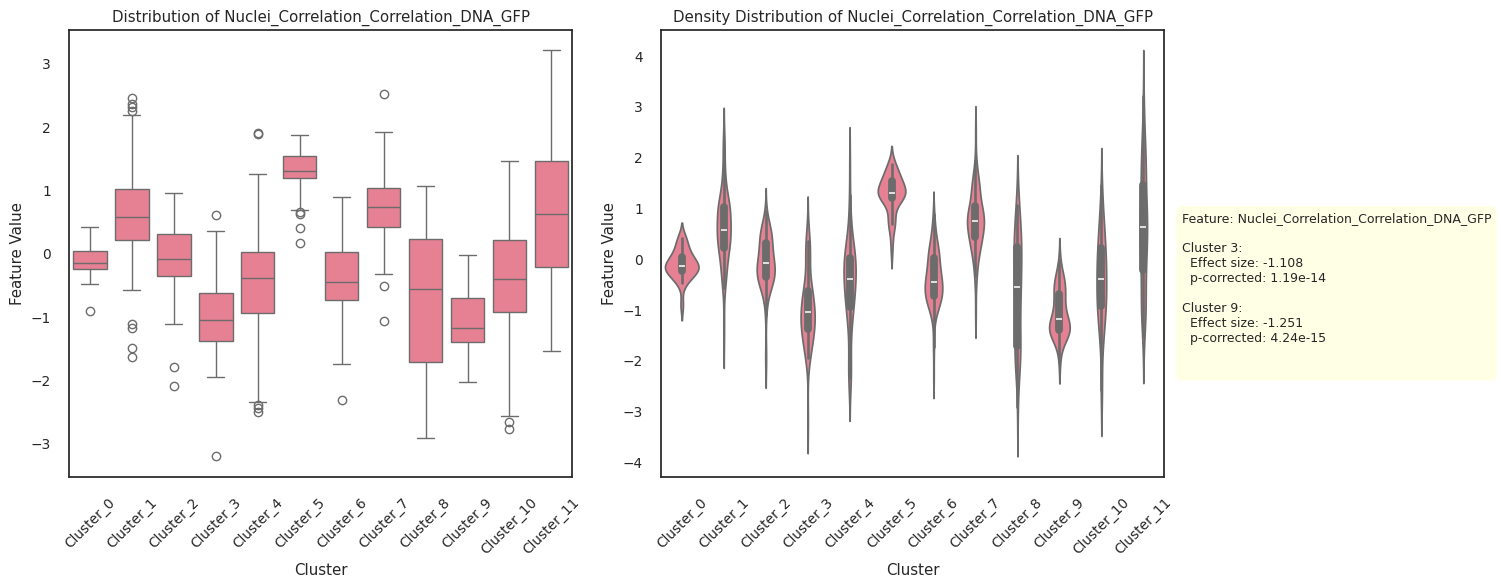

In [63]:
# If you want to use your original (non-scaled) data
fig_original = plot_feature_distribution(
    results_standard,
    "Nuclei_Correlation_Correlation_DNA_GFP",
    data_original=data_scaled_df,  # Use unscaled data
    clusters=cluster_dict,
    show_stats=True
)
plt.show()

In [70]:
map_clus_df.join(
    ref_var_cell_all_prof_df.unique(subset=["Metadata_gene_allele","Metadata_hpa_main_loc","Metadata_final_loc"]),
    left_on="gene",
    right_on="Metadata_gene_allele"
).filter(
    (pl.col("cluster")==3) & (pl.col("Metadata_hpa_main_loc")!="Uncertain") & (pl.col("index").is_in(hits_allele_list))
).unique(subset=["index", "Metadata_hpa_main_loc", "Metadata_final_loc"]).select(
    ["index", "Metadata_hpa_main_loc"]
).sort("index")

index,Metadata_hpa_main_loc
str,str
"""AGXT_Gly116Arg""","""Vesicles"""
"""AGXT_Ile202Asn""","""Vesicles"""
"""AIPL1_Met79Thr""","""Nuclear speckles"""
"""MLH1_Leu653Pro""","""Nucleoplasm"""
"""STXBP1_Arg190Gln""","""Cytosol;Nucleoplasm"""
"""STXBP1_Arg406Leu""","""Cytosol;Nucleoplasm"""
"""STXBP1_Asp238Glu""","""Cytosol;Nucleoplasm"""


In [ ]:
map_clus_df.join(
    ref_var_cell_all_prof_df.unique(subset=["Metadata_gene_allele","Metadata_hpa_main_loc","Metadata_final_loc"]),
    left_on="gene",
    right_on="Metadata_gene_allele"
).filter(
    (pl.col("cluster")==3) & (pl.col("Metadata_hpa_main_loc")!="Uncertain") & (pl.col("index").is_in(hits_allele_list))
).unique(subset=["index", "Metadata_hpa_main_loc", "Metadata_final_loc"]).select(
    ["index", "Metadata_hpa_main_loc"]
).sort("index")

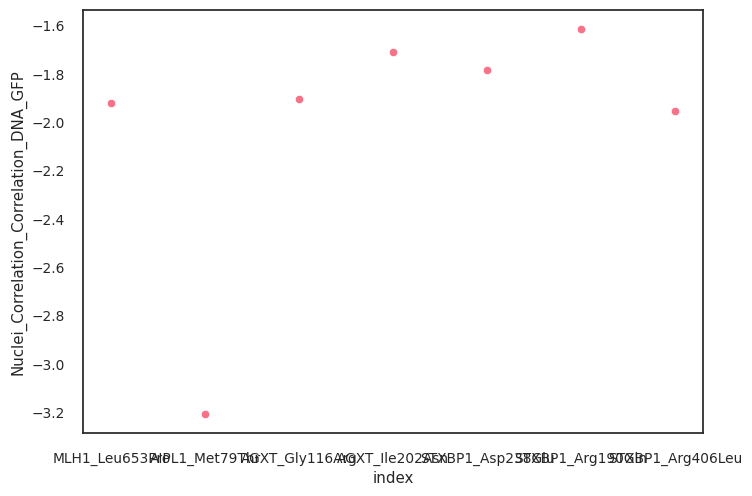

In [84]:
sns.scatterplot(
    data=df_clustered[(df_clustered["cluster"]==3)&(df_clustered["mislocalized"])].reset_index(),
    x="index",
    y="Nuclei_Correlation_Correlation_DNA_GFP"
)
plt.show()

In [83]:
df_clustered[(df_clustered["cluster"]==3)&(df_clustered["mislocalized"])]

,Cells_Texture_InfoMeas1_GFP_5_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Nuclei_Correlation_RWC_GFP_Mito,Cells_Correlation_RWC_DNA_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cells_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,Cells_Correlation_RWC_AGP_GFP,...,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Texture_Correlation_GFP_5_00_256,Nuclei_Correlation_RWC_DNA_GFP,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_Correlation_Correlation_GFP_Mito,Cells_Texture_Correlation_GFP_10_01_256,cluster,mislocalized
MLH1_Leu653Pro,1.042715,0.864910,1.292001,-1.473421,0.115752,-2.768847,-1.677266,-1.902861,1.095023,-0.464749,...,-2.101146,-1.645243,-0.849397,-2.314746,0.630253,-0.516251,0.150983,-2.180789,3,True
AIPL1_Met79Thr,1.826507,2.054635,0.370932,0.414453,-0.640111,1.540276,-0.916836,-2.012186,0.342308,0.623714,...,1.549132,-1.585830,-1.449971,0.807751,0.277483,-0.233082,-2.314746,-2.152702,3,True
AGXT_Gly116Arg,0.288666,1.576455,0.735402,0.510123,0.980007,1.812448,-0.841717,-1.310793,1.473421,0.613956,...,1.734806,-1.129931,-0.420313,1.104859,1.033508,-1.033508,-1.310793,-1.135031,3,True
AGXT_Ile202Asn,0.704081,1.785359,0.958525,0.534753,1.273654,2.152702,-1.166273,-1.221033,1.215392,0.830289,...,1.992252,-1.310793,-0.479763,1.114804,0.920933,-1.249840,-1.001950,-1.273654,3,True
STXBP1_Asp238Glu,0.353723,0.591410,1.391047,0.051055,-0.458773,0.202826,0.131992,-1.292001,1.056695,0.271905,...,-0.233082,-0.636818,-0.925045,-0.704081,0.288666,0.446870,0.148267,-1.155734,3,True
STXBP1_Arg190Gln,0.841717,0.837895,1.279722,0.476752,0.721394,0.807751,-0.202826,-1.391047,-0.059125,0.458773,...,0.676810,-0.884599,-0.553439,0.423249,-0.032237,-0.362314,0.235843,-0.993116,3,True
STXBP1_Arg406Leu,0.771072,0.868821,1.489516,-0.302696,0.373810,0.929173,-0.333777,-1.540276,-0.452813,-0.099543,...,0.686977,-0.920933,-1.273654,0.328102,0.429132,0.096844,-0.845551,-1.267633,3,True


In [77]:
df_clustered.reset_index()

,index,Cells_Texture_InfoMeas1_GFP_5_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Nuclei_Correlation_RWC_GFP_Mito,Cells_Correlation_RWC_DNA_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cells_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_8of10,...,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Texture_Correlation_GFP_5_00_256,Nuclei_Correlation_RWC_DNA_GFP,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_Correlation_Correlation_GFP_Mito,Cells_Texture_Correlation_GFP_10_01_256,cluster,mislocalized
0,SDHD_Gly138Val,-0.771072,-0.002686,-1.193206,0.663362,-0.626980,0.623714,0.411528,0.104943,0.285867,...,0.767461,0.348010,1.261657,-0.646719,0.365183,-0.967064,-0.683580,-0.048365,0,False
1,SDHD_Ala90Glu,-0.646719,-0.676810,-0.227566,-0.528566,-1.330060,-0.376692,0.556573,0.868821,0.690381,...,-0.288666,0.494886,-0.804035,-0.385357,-0.626980,-0.601035,-1.056695,-0.024176,0,False
2,SDHD_His102Pro,-0.896579,-0.519322,-0.826503,-0.233082,-1.699610,-0.348010,0.975674,0.984358,0.774693,...,-0.271905,0.984358,0.126575,-0.266335,-0.550312,-0.714443,-0.988727,0.640111,0,False
3,SDHD_Asp92Gly,-0.900601,-0.368056,-0.845551,-0.391149,-1.645243,0.288666,0.746003,0.857128,0.670071,...,0.164581,0.680191,0.693794,-0.131992,-0.760270,-0.724883,-0.516251,0.700644,0,False
4,SDHD_Arg70Thr,-0.912755,-0.585023,-0.476752,-0.432078,-2.054635,-0.096844,0.997523,1.226713,1.221033,...,-0.045676,0.826503,0.663362,-0.373810,0.094146,-0.760270,-0.394050,0.578661,0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
928,TPM1_Ala239Thr,-0.345158,-0.294271,0.274693,-0.123868,0.005372,-0.271905,0.414453,0.216554,0.479763,...,-0.414453,0.446870,-0.104943,-0.519322,-0.053744,-0.164581,-0.080665,0.099543,6,False
929,TPM1_Glu40Lys,-0.316785,-0.208312,0.072583,-0.040300,-0.118457,-0.299885,0.291467,-0.026862,-0.118457,...,-0.513185,0.399862,-0.470742,-0.849397,-0.271905,0.129283,-0.796635,-0.205568,6,False
930,TPM1_Arg160His,-0.440942,-0.540961,-0.153700,-0.238605,-0.126575,-0.373810,0.830289,0.150983,-0.336618,...,-0.494886,0.868821,-0.626980,-0.666712,-0.246904,0.048365,-0.510123,0.291467,6,False
931,TPM1_Lys248Glu,0.271905,0.263553,-0.183670,0.018802,-0.235843,0.191871,0.391149,0.034924,0.861012,...,-0.191871,0.420313,0.048365,-0.359447,0.280276,0.077970,-0.643411,0.126575,6,False
